## **Classificação de texto com ML**

**Dataset:** Depression: Reddit Dataset (Cleaned)

### **Instalação de pacotes** 📦

In [1]:
!python -m spacy download en_core_web_sm

C:\Users\there\AppData\Local\Python\pythoncore-3.14-64\python.exe: No module named spacy


### **Importando bibliotecas** 📚

In [2]:
import pandas as pd
import numpy as np
import re
import nltk
import spacy

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from string import punctuation
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud

### **Carregando dataset** 🔃

In [3]:
ARQUIVO = "depression_dataset_reddit_cleaned.csv"

dataset = pd.read_csv(ARQUIVO)

TEXT = "clean_text"
TARGET = "is_depression"
dataset.head()

,clean_text,is_depression
0,we understand that most people who reply immed...,1
1,welcome to r depression s check in post a plac...,1
2,anyone else instead of sleeping more when depr...,1
3,i ve kind of stuffed around a lot in my life d...,1
4,sleep is my greatest and most comforting escap...,1


### **Entendimento inicial dos dados** 🔎

In [4]:
print("Dimensão do dataset:", dataset.shape)

print("\nColunas:")
print(dataset.columns.tolist())

print("\nTipos:")
print(dataset.dtypes)

print("\nValores ausentes:")
print(dataset.isnull().sum())

print("\nDuplicados:")
print(dataset.duplicated().sum())

Dimensão do dataset: (7731, 2)

Colunas:
['clean_text', 'is_depression']

Tipos:
clean_text         str
is_depression    int64
dtype: object

Valores ausentes:
clean_text       0
is_depression    0
dtype: int64

Duplicados:
81


### **Preparando dados (Pré-processamento)** ⚙

In [5]:

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

# Modelo spaCy para inglês
nlp = spacy.load("en_core_web_sm")

# Stopwords em inglês
stopwords_en = set(stopwords.words("english"))

# Preservação de palavras de negação importantes
negacoes = {"no", "not", "nor", "never"}
stopwords_en = stopwords_en - negacoes

# Stemmer para inglês
stemmer = SnowballStemmer("english")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\there\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\there\AppData\Roaming\nltk_data...


[nltk_data]   Unzipping tokenizers\punkt.zip.


[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\there\AppData\Roaming\nltk_data...


[nltk_data]   Unzipping tokenizers\punkt_tab.zip.


In [6]:
def processar_texto(texto, is_stemming=True):

    texto = str(texto)

    # 1. Normalização
    texto = texto.lower()
    texto = re.sub(r'https?://\S+|www\.\S+', '', texto)
    texto = re.sub(r'[^\w\s]', '', texto)
    texto = re.sub(r'\s+', ' ', texto).strip()
    texto = ''.join(c for c in texto if c not in punctuation)

    # 2. Tokenização
    texto_tokenizado = nltk.word_tokenize(texto, language="english")

    # 3. Remoção de stopwords e tokens muito curtos
    # "no", "not", "nor" e "never" foram preservados por serem importantes
    # para o significado de frases relacionadas à saúde mental.
    texto_sem_stopwords = [
        token for token in texto_tokenizado
        if token not in stopwords_en and len(token) > 2
    ]

    # Atenção: usar Stemming OU Lematização, não ambos.
    if is_stemming:
        texto_processado = [
            stemmer.stem(token) for token in texto_sem_stopwords
        ]
    else:
        doc = nlp(" ".join(texto_sem_stopwords))
        texto_processado = [
            token.lemma_ for token in doc
        ]

    # Converte a lista de tokens em uma string
    texto_processado = " ".join(texto_processado)

    return texto_processado

### **Tratamento de registros ausentes e duplicados** 🧹

In [7]:
print("Registros antes da limpeza:", len(dataset))

# Remove valores ausentes nas colunas utilizadas
dataset = dataset.dropna(subset=[TEXT, TARGET]).copy()

# Remove textos vazios
dataset[TEXT] = dataset[TEXT].astype(str).str.strip()
dataset = dataset[dataset[TEXT] != ""].copy()

# Remove registros duplicados
dataset = dataset.drop_duplicates().reset_index(drop=True)

print("Registros depois da limpeza:", len(dataset))

Registros antes da limpeza: 7731
Registros depois da limpeza: 7650


In [8]:
# Pré-processamento de todos os textos do dataset
data_process = dataset.copy()

old_texts = data_process[TEXT]
new_texts = []

for text in old_texts:
    text = processar_texto(text)
    new_texts.append(text)

data_process[TEXT] = new_texts

data_process.head()

,clean_text,is_depression
0,understand peopl repli immedi invit talk priva...,1
1,welcom depress check post place take moment sh...,1
2,anyon els instead sleep depress stay night avo...,1
3,kind stuf around lot life delay inevit work jo...,1
4,sleep greatest comfort escap whenev wake day l...,1


### **Balanceamento do conjunto de dados** 📊

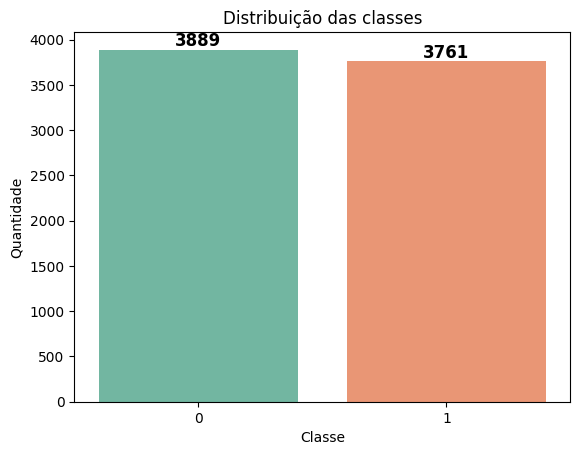


Distribuição percentual:
is_depression
0    50.84
1    49.16
Name: proportion, dtype: float64


In [9]:
ax = sns.countplot(
    x=TARGET,
    data=data_process,
    hue=TARGET,
    palette="Set2",
    legend=False
)

# Quantidade sobre cada barra
for container in ax.containers:
    ax.bar_label(container, fontsize=12, fontweight="bold")

plt.xlabel("Classe")
plt.ylabel("Quantidade")
plt.title("Distribuição das classes")
plt.show()

print("\nDistribuição percentual:")
print(
    data_process[TARGET]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

**Classes do dataset:**

- `0` = texto não relacionado à depressão
- `1` = texto relacionado à depressão

### **Nuvem de palavras** ☁

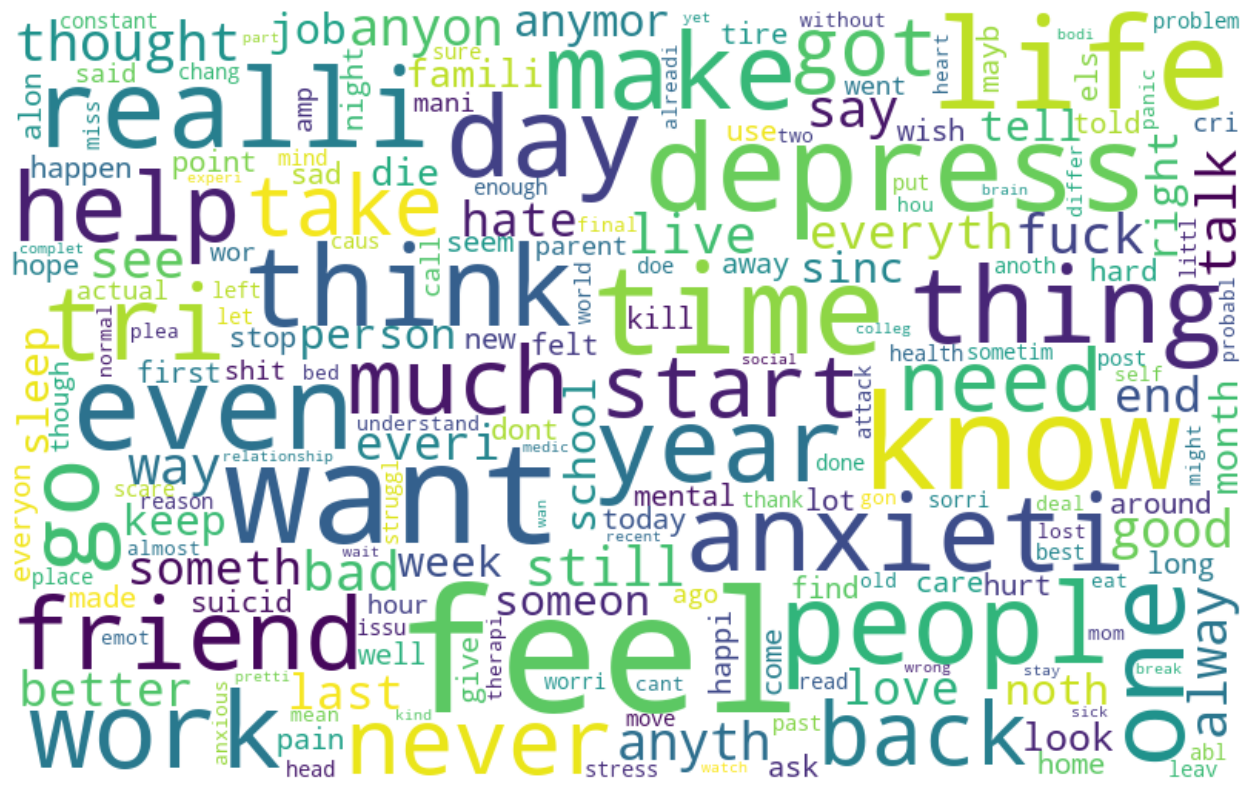

In [10]:
new_texts = data_process[TEXT]

all_words = ' '.join([text for text in new_texts])

word_cloud = WordCloud(
    width=800,
    height=500,
    max_font_size=110,
    background_color="white",
    collocations=False
).generate(all_words)

plt.figure(figsize=(20,10))
plt.imshow(word_cloud, interpolation='bilinear')
plt.axis("off")
plt.show()

### **Classificação de texto** 🤖

#### **Separação dos dados e vetorização TF-IDF**

In [11]:
# Separa primeiro os textos em treino e teste.
# A divisão é estratificada para preservar a proporção das classes.

train_texts, test_texts, train_label, test_label = train_test_split(
    data_process[TEXT],
    data_process[TARGET],
    test_size=0.20,
    random_state=42,
    stratify=data_process[TARGET]
)

print("Treino:", len(train_texts))
print("Teste:", len(test_texts))

print("\nDistribuição no treino:")
print(train_label.value_counts(normalize=True).sort_index())

print("\nDistribuição no teste:")
print(test_label.value_counts(normalize=True).sort_index())

Treino: 6120
Teste: 1530

Distribuição no treino:
is_depression
0    0.508333
1    0.491667
Name: proportion, dtype: float64

Distribuição no teste:
is_depression
0    0.508497
1    0.491503
Name: proportion, dtype: float64


In [12]:
# Cria o vetorizador TF-IDF
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    sublinear_tf=True,
    min_df=2
)

# O vocabulário é aprendido SOMENTE no conjunto de treino,
# evitando vazamento de dados.
train_df = tfidf.fit_transform(train_texts)

# O conjunto de teste é apenas transformado com o vocabulário aprendido
test_df = tfidf.transform(test_texts)

print("Formato do conjunto de treino:", train_df.shape)
print("Formato do conjunto de teste:", test_df.shape)

Formato do conjunto de treino: (6120, 27934)
Formato do conjunto de teste: (1530, 27934)


#### **Treinando algoritmos de Machine Learning**

##### **1. Regressão Logística**

In [13]:
LogisticRegressionModel = LogisticRegression(
    max_iter=2000,
    random_state=42
)

LogisticRegressionModel.fit(train_df, train_label)


,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

##### **2. Random Forest**

In [14]:
RandomForest = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

RandomForest.fit(train_df, train_label)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

##### **3. k-Nearest Neighbors (k-NN)**

In [15]:
KNN = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    metric="cosine",
    algorithm="brute"
)

KNN.fit(train_df, train_label)


,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'distance'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'brute'
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'cosine'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'cosine'


#### **Testando os modelos de Machine Learning**

In [16]:
pred_logistic_test = LogisticRegressionModel.predict(test_df)
pred_rf_test = RandomForest.predict(test_df)
pred_knn_test = KNN.predict(test_df)


### **Função para exibir a matriz de confusão**

In [17]:
def show_confusion_matrix(confusion_matrix):
    hmap = sns.heatmap(
        confusion_matrix,
        annot=True,
        fmt="d",
        cmap="Greens"
    )

    hmap.yaxis.set_ticklabels(
        hmap.yaxis.get_ticklabels(),
        rotation=0,
        ha='right'
    )

    hmap.xaxis.set_ticklabels(
        hmap.xaxis.get_ticklabels(),
        rotation=30,
        ha='right'
    )

    plt.ylabel('Saída real')
    plt.xlabel('Saída predita')

### **Regressão Logística — Matriz de confusão**

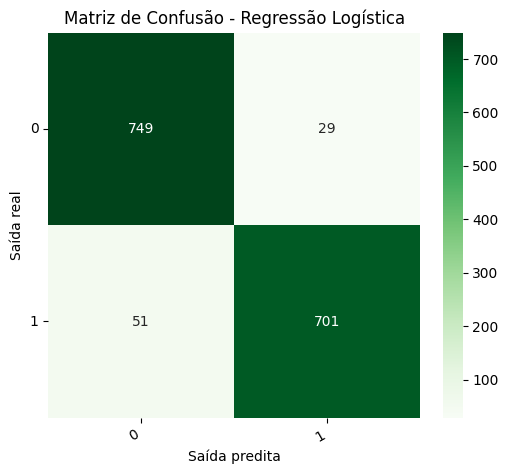

In [18]:
cm_LR = confusion_matrix(test_label, pred_logistic_test)

plt.figure(figsize=(6,5))
show_confusion_matrix(cm_LR)
plt.title("Matriz de Confusão - Regressão Logística")
plt.show()


### **Regressão Logística — Métricas**

In [19]:
print(classification_report(test_label, pred_logistic_test))


              precision    recall  f1-score   support

           0       0.94      0.96      0.95       778
           1       0.96      0.93      0.95       752

    accuracy                           0.95      1530
   macro avg       0.95      0.95      0.95      1530
weighted avg       0.95      0.95      0.95      1530



### **Random Forest — Matriz de confusão**

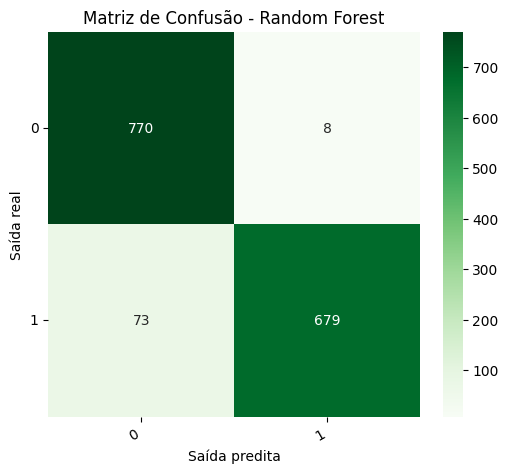

In [20]:
cm_RF = confusion_matrix(test_label, pred_rf_test)

plt.figure(figsize=(6,5))
show_confusion_matrix(cm_RF)
plt.title("Matriz de Confusão - Random Forest")
plt.show()


### **Random Forest — Métricas**

In [21]:
print(classification_report(test_label, pred_rf_test))


              precision    recall  f1-score   support

           0       0.91      0.99      0.95       778
           1       0.99      0.90      0.94       752

    accuracy                           0.95      1530
   macro avg       0.95      0.95      0.95      1530
weighted avg       0.95      0.95      0.95      1530



### **k-NN — Matriz de confusão**

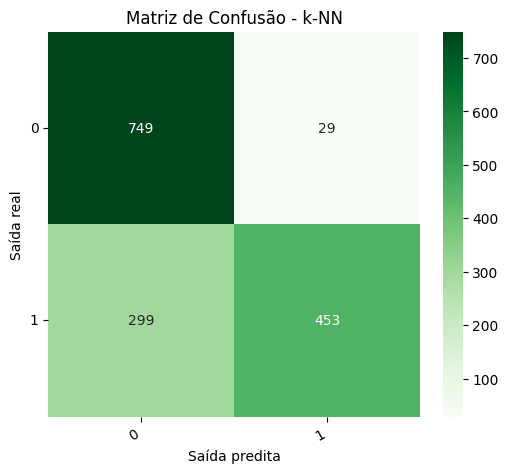

In [22]:
cm_KNN = confusion_matrix(test_label, pred_knn_test)

plt.figure(figsize=(6,5))
show_confusion_matrix(cm_KNN)
plt.title("Matriz de Confusão - k-NN")
plt.show()


### **k-NN — Métricas**

In [23]:
print(classification_report(test_label, pred_knn_test))


              precision    recall  f1-score   support

           0       0.71      0.96      0.82       778
           1       0.94      0.60      0.73       752

    accuracy                           0.79      1530
   macro avg       0.83      0.78      0.78      1530
weighted avg       0.83      0.79      0.78      1530



### **Comparação dos três modelos** 📈

In [24]:
resultados = pd.DataFrame({
    "Modelo": [
        "Regressão Logística",
        "Random Forest",
        "k-NN"
    ],
    "Acurácia": [
        accuracy_score(test_label, pred_logistic_test),
        accuracy_score(test_label, pred_rf_test),
        accuracy_score(test_label, pred_knn_test)
    ],
    "Precisão": [
        precision_score(test_label, pred_logistic_test, zero_division=0),
        precision_score(test_label, pred_rf_test, zero_division=0),
        precision_score(test_label, pred_knn_test, zero_division=0)
    ],
    "Recall": [
        recall_score(test_label, pred_logistic_test, zero_division=0),
        recall_score(test_label, pred_rf_test, zero_division=0),
        recall_score(test_label, pred_knn_test, zero_division=0)
    ],
    "F1-score": [
        f1_score(test_label, pred_logistic_test, zero_division=0),
        f1_score(test_label, pred_rf_test, zero_division=0),
        f1_score(test_label, pred_knn_test, zero_division=0)
    ]
})

resultados.sort_values(
    by="F1-score",
    ascending=False
).round(4)


,Modelo,Acurácia,Precisão,Recall,F1-score
0,Regressão Logística,0.9477,0.9603,0.9322,0.9460
1,Random Forest,0.9471,0.9884,0.9029,0.9437
2,k-NN,0.7856,0.9398,0.6024,0.7342


### **Visualização da comparação dos modelos**

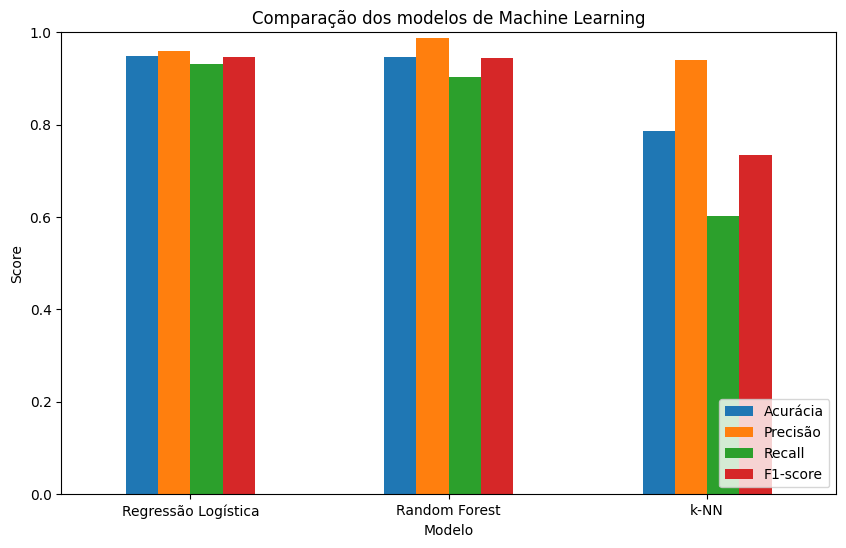

In [25]:
resultados_plot = resultados.set_index("Modelo")

resultados_plot.plot(
    kind="bar",
    figsize=(10,6)
)

plt.title("Comparação dos modelos de Machine Learning")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

### **Análise de erros do melhor modelo** 🔍

In [26]:
# Seleciona automaticamente o modelo com maior F1-score

melhor_modelo_nome = resultados.loc[
    resultados["F1-score"].idxmax(),
    "Modelo"
]

if melhor_modelo_nome == "Regressão Logística":
    melhor_pred = pred_logistic_test
elif melhor_modelo_nome == "Random Forest":
    melhor_pred = pred_rf_test
else:
    melhor_pred = pred_knn_test

print("Melhor modelo pelo F1-score:", melhor_modelo_nome)

analise_erros = pd.DataFrame({
    "texto": test_texts.reset_index(drop=True),
    "classe_real": test_label.reset_index(drop=True),
    "classe_predita": pd.Series(melhor_pred)
})

erros = analise_erros[
    analise_erros["classe_real"] != analise_erros["classe_predita"]
]

print("Quantidade de erros:", len(erros))

erros.head(20)


Melhor modelo pelo F1-score: Regressão Logística
Quantidade de erros: 80


,texto,classe_real,classe_predita
5,given,1,0
13,birutagm yeah realli depress stuff like get,0,1
23,regret ever seek help hotlin wait long basic m...,1,0
31,somebodi pleas give kind word wait clonezapam ...,1,0
61,feel well still get peopl say pregnanc beautif...,0,1
93,vanidosa wrong need inhal even know sick hope ...,0,1
100,realiz normal horribl mean work job hate bare ...,1,0
107,ispahanjahan psychologu dupont mari estell tra...,1,0
141,noth life enjoy not mention like miss assign c...,1,0
167,babi shower person know expect mom sit tabl ha...,1,0


#### **Falsos positivos**

In [27]:
falsos_positivos = erros[
    (erros["classe_real"] == 0) &
    (erros["classe_predita"] == 1)
]

print("Quantidade de falsos positivos:", len(falsos_positivos))

falsos_positivos.head(10)

Quantidade de falsos positivos: 29


,texto,classe_real,classe_predita
13,birutagm yeah realli depress stuff like get,0,1
61,feel well still get peopl say pregnanc beautif...,0,1
93,vanidosa wrong need inhal even know sick hope ...,0,1
228,whitout friend,0,1
233,justgelo sad know found bodi crazi world live ...,0,1
321,day feel like twitter know,0,1
328,fleuryli either depress think even want know k...,0,1
372,kevchoic get person mind could even ish like p...,0,1
469,kcarruth year old pixi year,0,1
525,horror wench toooooo feel like verg anxieti at...,0,1


#### **Falsos negativos**

In [28]:
falsos_negativos = erros[
    (erros["classe_real"] == 1) &
    (erros["classe_predita"] == 0)
]

print("Quantidade de falsos negativos:", len(falsos_negativos))

falsos_negativos.head(10)

Quantidade de falsos negativos: 51


,texto,classe_real,classe_predita
5,given,1,0
23,regret ever seek help hotlin wait long basic m...,1,0
31,somebodi pleas give kind word wait clonezapam ...,1,0
100,realiz normal horribl mean work job hate bare ...,1,0
107,ispahanjahan psychologu dupont mari estell tra...,1,0
141,noth life enjoy not mention like miss assign c...,1,0
167,babi shower person know expect mom sit tabl ha...,1,0
268,life rush toward 0km instead go forward stand ...,1,0
296,get,1,0
307,think tri tonight late night walk accident tri...,1,0
